# Stage 1: Perspective-Aware YOLO + ByteTrack Candidate Gate (CPU Optimized)
**Focus:** High-recall spatial/temporal filtering, event deduplication, CPU profiling, and ROI handoff manifest generation for Stage 2 VLM verification.

In [14]:
import sys
import os
import re
import time
import json
import glob
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import scipy.io as sio
from PIL import Image
from IPython.display import display, clear_output
from ultralytics import YOLO

# Ensure Python can find local repository scripts
PROJECT_ROOT = Path().resolve()
if (PROJECT_ROOT / "scripts").exists():
    sys.path.insert(0, str(PROJECT_ROOT))
else:
    sys.path.insert(0, str(PROJECT_ROOT.parent))

# Output directory for VLM teammate handoff
HANDOFF_DIR = PROJECT_ROOT / "vlm_handoff"
CROPS_DIR = HANDOFF_DIR / "crops"
FRAMES_DIR = HANDOFF_DIR / "annotated_frames"
CROPS_DIR.mkdir(parents=True, exist_ok=True)
FRAMES_DIR.mkdir(parents=True, exist_ok=True)

print(f"✅ Cell 1 Loaded! VLM handoff artifacts will be saved to: {HANDOFF_DIR}")

✅ Cell 1 Loaded! VLM handoff artifacts will be saved to: /Users/ianvarella/capstone_S25/notebooks/vlm_handoff


In [ ]:
# =====================================================================
# CELL 2: GLOBAL CONFIGURATION & STRICT CLASS FILTER
# =====================================================================
MODEL_WEIGHTS = "yolov8n.pt"   # Options: "yolov8n.pt", "yolov8n.onnx", "yolov8n_openvino_model"
IMGSZ = 640                    # Options: 640, 480, 384
VID_STRIDE = 1                 # Options: 1 (30 FPS), 2 (15 FPS), 3 (10 FPS)

CONF_THRESH = 0.22             # Lowered to catch small bags/cups/bottles on floor
PERSON_CONF_MIN = 0.45         # Stricter confidence for person class

# STRICT ACTOR + PORTABLE ITEM FILTER (Ignores chairs, tables, monitors, static furniture)
# COCO IDs: 0=person, 24=backpack, 25=umbrella, 26=handbag, 28=suitcase, 39=bottle, 41=cup
TARGET_CLASSES = [0, 24, 25, 26, 28, 39, 41]
PORTABLE_ITEM_NAMES = {"backpack", "umbrella", "handbag", "suitcase", "bag", "bottle", "cup"}

CLIP_PADDING_SEC = 2.5         # Seconds before/after trigger for VLM review clip window
SHOW_LIVE_DISPLAY = True       # Set False when running fast benchmarks

model = YOLO(MODEL_WEIGHTS)
print(f"✅ Cell 2 Loaded: {MODEL_WEIGHTS} | imgsz={IMGSZ} | stride={VID_STRIDE}")

✅ Cell 2 Loaded: yolo26m.pt | imgsz=640 | stride=1


In [16]:
# =====================================================================
# CELL 3: BYTETRACK MEMORY BUFFER CONFIGURATION (Fixed for Ultralytics)
# =====================================================================
effective_fps = max(1, int(30 // VID_STRIDE))
scaled_buffer = max(30, int(120 // VID_STRIDE))

custom_tracker_content = f"""tracker_type: bytetrack
track_high_thresh: 0.45
track_low_thresh: 0.1
new_track_thresh: 0.5
match_thresh: 0.8
track_buffer: {scaled_buffer}
frame_rate: {effective_fps}
fuse_score: True
"""

with open("custom_tracker.yaml", "w") as f:
    f.write(custom_tracker_content.strip())

print(f"✅ Cell 3 Fixed: custom_tracker.yaml updated with fuse_score: True (track_buffer={scaled_buffer})")

✅ Cell 3 Fixed: custom_tracker.yaml updated with fuse_score: True (track_buffer=120)


In [17]:
# =====================================================================
# CELL 4: UNIFIED STAGE 1 RULE ENGINE
# - Rule 1A (Smoking Snapshot): 1 crop when person is stably tracked (0.5s) or in static image
# - Rule 1B (Zone-Radius): Loitering / Rough Sleeping / Stationary Smoking (>5s within 0.6x height radius)
# - Rule 2A (Unattended Bag): Human-drop causality + 3s separation
# - Rule 2B (Littering): MOG2 background subtraction contour appearing in person's wake
# =====================================================================
TRACK_HISTORY = {}
UNATTENDED_ITEMS = {}
CANDIDATE_MANIFEST = []
OLD_RULE_RAW_FRAME_TRIGGERS = 0
BG_SUBTRACTOR = cv2.createBackgroundSubtractorMOG2(history=150, varThreshold=36, detectShadows=False)

def reset_all_state():
    global OLD_RULE_RAW_FRAME_TRIGGERS, BG_SUBTRACTOR
    TRACK_HISTORY.clear()
    UNATTENDED_ITEMS.clear()
    CANDIDATE_MANIFEST.clear()
    OLD_RULE_RAW_FRAME_TRIGGERS = 0
    BG_SUBTRACTOR = cv2.createBackgroundSubtractorMOG2(history=150, varThreshold=36, detectShadows=False)
    
    # Safely reset Ultralytics ByteTrack state between videos without deleting the tracker list
    if hasattr(model, "predictor") and model.predictor is not None:
        if hasattr(model.predictor, "trackers") and model.predictor.trackers:
            for t in model.predictor.trackers:
                t.reset()
        else:
            model.predictor = None

def save_vlm_handoff_crops(frame, box, event_id, pad_ratio=0.40):
    h, w, _ = frame.shape
    x1, y1, x2, y2 = box
    bw, bh = x2 - x1, y2 - y1
    cx1 = max(0, int(x1 - bw * pad_ratio))
    cy1 = max(0, int(y1 - bh * pad_ratio))
    cx2 = min(w, int(x2 + bw * pad_ratio))
    cy2 = min(h, int(y2 + bh * pad_ratio))
    
    crop_img = frame[cy1:cy2, cx1:cx2]
    crop_path = CROPS_DIR / f"{event_id}_crop.jpg"
    cv2.imwrite(str(crop_path), crop_img)
    
    annotated = frame.copy()
    cv2.rectangle(annotated, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), 3)
    frame_path = FRAMES_DIR / f"{event_id}_context.jpg"
    cv2.imwrite(str(frame_path), annotated)
    return str(crop_path), str(frame_path)

def run_person_rules(track_id, cls_name, conf, box, frame_id, stride=1, fps=30.0, loiter_sec=5.0, is_static_image=False):
    """
    Handles Rule 1A (Initial Actor Snapshot for Walking Smokers / Static Images)
    and Rule 1B (Zone-Radius Presence for Loitering / Rough Sleeping).
    """
    global OLD_RULE_RAW_FRAME_TRIGGERS
    if cls_name != "person" or conf < PERSON_CONF_MIN:
        return []
        
    events = []
    x1, y1, x2, y2 = box
    cx, cy = (x1 + x2) / 2.0, (y1 + y2) / 2.0
    person_h = max(1.0, float(y2 - y1))
    
    window_steps = max(5, int((loiter_sec * fps) / stride))
    snapshot_steps = 1 if is_static_image else max(3, int((0.5 * fps) / stride)) # 0.5s stability check
    
    if track_id not in TRACK_HISTORY:
        TRACK_HISTORY[track_id] = {
            "start_frame": frame_id,
            "last_seen_frame": frame_id,
            "positions": [],
            "foot_history": [],
            "snapshot_taken": False,
            "loiter_flagged": False
        }
        
    hist = TRACK_HISTORY[track_id]
    hist["last_seen_frame"] = frame_id
    hist["positions"].append((cx, cy))
    hist["foot_history"].append((frame_id, cx, float(y2), person_h))
    
    max_foot_steps = max(10, int((4.0 * fps) / stride))
    if len(hist["foot_history"]) > max_foot_steps:
        hist["foot_history"].pop(0)
        
    # --- RULE 1A: INITIAL ACTOR SNAPSHOT (Catches walking smokers & single-frame datasets) ---
    if not hist["snapshot_taken"] and len(hist["positions"]) >= snapshot_steps:
        hist["snapshot_taken"] = True
        events.append({
            "event_id": f"snapshot_t{track_id}_f{frame_id}",
            "event_type": "actor_snapshot_smoking_check",
            "entity_id": f"person_{track_id}",
            "start_frame": hist["start_frame"],
            "trigger_frame": frame_id,
            "timestamp_s": round(frame_id / fps, 2),
            "clip_window_s": [round(max(0.0, (frame_id / fps) - CLIP_PADDING_SEC), 2),
                              round((frame_id / fps) + CLIP_PADDING_SEC, 2)],
            "roi_box": [int(x1), int(y1), int(x2), int(y2)],
            "vlm_prompt_hint": "Inspect person upper body/hands: check if person is smoking or carrying prohibited items."
        })

    # --- RULE 1B: ZONE-RADIUS PRESENCE (Catches Loitering, Rough Sleeping, Stationary Smoking) ---
    if len(hist["positions"]) > window_steps:
        hist["positions"].pop(0)
        pts = np.array(hist["positions"])
        centroid = np.mean(pts, axis=0)
        # Max distance from the person's rolling center in the last 5 seconds
        max_radius_px = float(np.max(np.hypot(pts[:, 0] - centroid[0], pts[:, 1] - centroid[1])))
        norm_radius = max_radius_px / person_h
        
        start_x, start_y = hist["positions"][0]
        raw_dist = float(np.hypot(cx - start_x, cy - start_y))
        duration_frames = frame_id - hist["start_frame"]
        
        if duration_frames > int(loiter_sec * fps) and raw_dist < 40:
            OLD_RULE_RAW_FRAME_TRIGGERS += 1
            
        # Trigger if person stayed within a radius of 0.60x their body height for the entire window
        if duration_frames >= int(loiter_sec * fps) and norm_radius < 0.60:
            if not hist["loiter_flagged"]:
                hist["loiter_flagged"] = True
                events.append({
                    "event_id": f"zone_loiter_t{track_id}_f{frame_id}",
                    "event_type": "sustained_zone_presence",
                    "entity_id": f"person_{track_id}",
                    "start_frame": hist["start_frame"],
                    "trigger_frame": frame_id,
                    "timestamp_s": round(frame_id / fps, 2),
                    "clip_window_s": [round(max(0.0, (frame_id / fps) - CLIP_PADDING_SEC), 2),
                                      round((frame_id / fps) + CLIP_PADDING_SEC, 2)],
                    "roi_box": [int(x1), int(y1), int(x2), int(y2)],
                    "metrics": {"zone_radius_px": round(max_radius_px, 1), "norm_radius_ratio": round(norm_radius, 3)},
                    "vlm_prompt_hint": "Person remained in the same zone for >5s. Classify as loitering, rough sleeping, smoking, or normal waiting."
                })
        elif norm_radius >= 0.90:
            hist["loiter_flagged"] = False
            
    return events

def was_person_recently_near(bx, by, curr_frame_id, fps=30.0, lookback_sec=3.5):
    max_frame_age = int(lookback_sec * fps)
    for track_id, hist in TRACK_HISTORY.items():
        if (curr_frame_id - hist.get("last_seen_frame", -9999)) > max_frame_age:
            continue
        for f_id, px, py_feet, p_h in hist.get("foot_history", []):
            if (curr_frame_id - f_id) <= max_frame_age:
                py_torso = py_feet - (0.5 * p_h)
                if min(np.hypot(bx - px, by - py_feet), np.hypot(bx - px, by - py_torso)) < (1.6 * p_h):
                    return True
    return False

def check_objects_and_litter_v2(frame, boxes, classes, confs, model_names, curr_frame_id, stride=1, fps=30.0, unattended_sec=3.0):
    """
    Handles Rule 2A (Unattended Bags via YOLO + Human-Drop Causality)
    and Rule 2B (Small Littering Blobs via MOG2 Background Subtraction near a person).
    """
    global OLD_RULE_RAW_FRAME_TRIGGERS
    persons = []
    candidate_objects = []
    
    for box, cls_idx, conf in zip(boxes, classes, confs):
        cls_name = model_names[int(cls_idx)]
        x1, y1, x2, y2 = box
        cx, cy = (x1 + x2) / 2.0, (y1 + y2) / 2.0
        
        if cls_name == "person" and conf >= PERSON_CONF_MIN:
            persons.append({"feet": (cx, float(y2)), "center": (cx, cy), "height": max(1.0, float(y2 - y1)), "box": box})
        elif cls_name in PORTABLE_ITEM_NAMES:
            diag = max(1.0, float(np.hypot(x2 - x1, y2 - y1)))
            candidate_objects.append({"box": [int(x1), int(y1), int(x2), int(y2)], "center": (cx, cy), "diag": diag, "cls": cls_name})
            
    # --- ADD MOG2 BACKGROUND SUBTRACTION CONTOURS FOR SMALL LITTER ---
    fg_mask = BG_SUBTRACTOR.apply(frame)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    fg_mask = cv2.morphologyEx(fg_mask, cv2.MORPH_OPEN, kernel)
    contours, _ = cv2.findContours(fg_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    for cnt in contours:
        area = cv2.contourArea(cnt)
        if 40 < area < 6000:  # Small-to-medium dropped trash filter
            x, y, w, h = cv2.boundingRect(cnt)
            cx, cy = x + w / 2.0, y + h / 2.0
            # Avoid duplicating an existing person bounding box
            inside_person = any((p["box"][0] <= cx <= p["box"][2] and p["box"][1] <= cy <= p["box"][3]) for p in persons)
            if not inside_person:
                diag = max(1.0, float(np.hypot(w, h)))
                candidate_objects.append({"box": [int(x), int(y), int(x + w), int(y + h)], "center": (cx, cy), "diag": diag, "cls": "litter_blob"})

    seen_ids = set()
    new_events = []
    unattended_thresh_frames = int(unattended_sec * fps)
    grace_steps = max(3, int((0.5 * fps) / stride))
    warmup_frames = int(1.0 * fps)
    
    for obj in candidate_objects:
        bx, by = obj["center"]
        is_near_person_now = False
        
        for p in persons:
            px, py_feet = p["feet"]
            py_torso = p["center"][1]
            if min(np.hypot(bx - px, by - py_feet), np.hypot(bx - px, by - py_torso)) < (1.5 * p["height"]):
                is_near_person_now = True
                break
                
        matched_id = None
        for o_id, data in UNATTENDED_ITEMS.items():
            last_bx, last_by = data["last_center"]
            if np.hypot(bx - last_bx, by - last_by) < max(35.0, 1.2 * obj["diag"]):
                matched_id = o_id
                break
                
        if matched_id is None:
            matched_id = f"{obj['cls']}_{int(bx)}_{int(by)}"
            
        seen_ids.add(matched_id)
        
        if matched_id not in UNATTENDED_ITEMS:
            dropped_by_human = is_near_person_now or was_person_recently_near(bx, by, curr_frame_id, fps=fps)
            is_preexisting = (curr_frame_id <= warmup_frames) and (not dropped_by_human)
            UNATTENDED_ITEMS[matched_id] = {
                "cls": obj["cls"],
                "start_frame": curr_frame_id,
                "last_center": (bx, by),
                "box": obj["box"],
                "was_attended": dropped_by_human and (not is_preexisting),
                "missing_steps": 0,
                "flagged": False
            }
        else:
            item = UNATTENDED_ITEMS[matched_id]
            item["last_center"] = (bx, by)
            item["box"] = obj["box"]
            item["missing_steps"] = 0
            if is_near_person_now and item["cls"] != "litter_blob":
                item["was_attended"] = True
                item["start_frame"] = curr_frame_id
                item["flagged"] = False
                
        item = UNATTENDED_ITEMS[matched_id]
        
        # For litter_blob: trigger if it spawned near a person and persisted for >= 0.4s
        req_frames = int(0.4 * fps) if item["cls"] == "litter_blob" else unattended_thresh_frames
        cond = item["was_attended"] and ((item["cls"] == "litter_blob") or (not is_near_person_now))
        
        if cond:
            duration = curr_frame_id - item["start_frame"]
            if duration >= req_frames:
                OLD_RULE_RAW_FRAME_TRIGGERS += 1
                if not item["flagged"]:
                    item["flagged"] = True
                    ev_type = "littering_candidate" if item["cls"] == "litter_blob" else "unattended_object"
                    new_events.append({
                        "event_id": f"{ev_type}_{matched_id}_f{curr_frame_id}",
                        "event_type": ev_type,
                        "entity_id": matched_id,
                        "start_frame": item["start_frame"],
                        "trigger_frame": curr_frame_id,
                        "timestamp_s": round(curr_frame_id / fps, 2),
                        "clip_window_s": [round(max(0.0, (curr_frame_id / fps) - CLIP_PADDING_SEC), 2),
                                          round((curr_frame_id / fps) + CLIP_PADDING_SEC, 2)],
                        "roi_box": item["box"],
                        "vlm_prompt_hint": "Object/debris appeared or was left behind by a person. Verify if littering or unattended bag."
                    })
                    
    for o_id in list(UNATTENDED_ITEMS.keys()):
        if o_id not in seen_ids:
            UNATTENDED_ITEMS[o_id]["missing_steps"] += 1
            if UNATTENDED_ITEMS[o_id]["missing_steps"] > grace_steps:
                del UNATTENDED_ITEMS[o_id]
                
    return new_events

print("✅ Cell 4 Loaded: Unified Stage 1 Rule Engine ready.")

✅ Cell 4 Loaded: Unified Stage 1 Rule Engine ready.


In [20]:
# =====================================================================
# CELL 5: LOAD SINGLE TEST VIDEO FOR VISUAL DEMO
# =====================================================================
TARGET_DIR = PROJECT_ROOT.parent / "data" / "loitering" / "testing_videos" # Change to your dataset folder for a single video demo
print(f"Scanning target directory: {TARGET_DIR}")

video_extensions = ('*.avi', '*.mp4', '*.mov', '*.mkv')
video_files = []
for ext in video_extensions:
    video_files.extend(glob.glob(str(TARGET_DIR / ext)))
    video_files.extend(glob.glob(str(TARGET_DIR / "**" / ext), recursive=True))
video_files = sorted(list(set(video_files)))

if video_files:
    SELECTED_VIDEO = video_files[0]
    cap = cv2.VideoCapture(SELECTED_VIDEO)
    VIDEO_FPS = cap.get(cv2.CAP_PROP_FPS) or 30.0
    TOTAL_FRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    TOTAL_DURATION_S = TOTAL_FRAMES / VIDEO_FPS
    print(f"🎬 Loaded: {Path(SELECTED_VIDEO).name} | FPS: {VIDEO_FPS:.1f} | Total Frames: {TOTAL_FRAMES} ({TOTAL_DURATION_S:.1f}s)")
else:
    print(f"⚠️ No single test video in {TARGET_DIR}. You can still run Cell 8 for the 3-Dataset Benchmark!")

Scanning target directory: /Users/ianvarella/capstone_S25/data/loitering/testing_videos
🎬 Loaded: 01.avi | FPS: 25.0 | Total Frames: 1439 (57.6s)


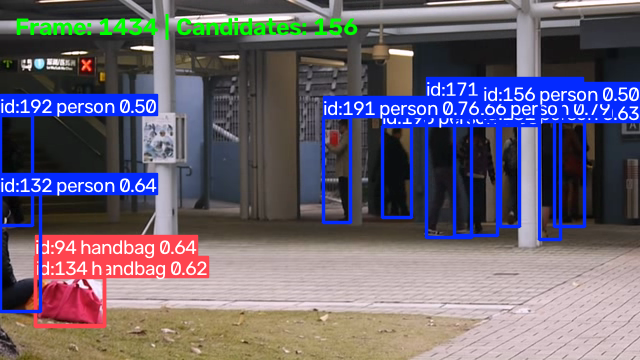

✅ Processed 1439 frames (1439 steps) in 165.05s.


In [21]:
# =====================================================================
# CELL 6: RUN STAGE 1 ON SINGLE VIDEO & SAVE VLM HANDOFF CROPS
# =====================================================================
if video_files:
    reset_all_state()
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
    frame_id = 0
    processed_steps = 0
    step_latencies = []
    t_start_total = time.perf_counter()

    try:
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break
            curr_id = frame_id
            frame_id += 1
            if curr_id % VID_STRIDE != 0:
                continue

            t0 = time.perf_counter()
            results = model.track(
                frame, persist=True, tracker="custom_tracker.yaml",
                imgsz=IMGSZ, conf=CONF_THRESH, classes=TARGET_CLASSES, verbose=False
            )
            annotated_frame = results[0].plot() if SHOW_LIVE_DISPLAY else frame

            if results[0].boxes is not None and len(results[0].boxes) > 0:
                boxes = results[0].boxes.xyxy.cpu().numpy()
                classes = results[0].boxes.cls.int().cpu().tolist()
                confs = results[0].boxes.conf.cpu().tolist()
                track_ids = results[0].boxes.id.int().cpu().tolist() if results[0].boxes.id is not None else list(range(1, len(boxes)+1))

                # 1. Person Rules (Smoking Snapshot + Zone-Radius Loitering/Sleeping)
                for box, track_id, cls_idx, conf in zip(boxes, track_ids, classes, confs):
                    cls_name = model.names[int(cls_idx)]
                    p_events = run_person_rules(track_id, cls_name, conf, box, curr_id, stride=VID_STRIDE, fps=VIDEO_FPS)
                    for ev in p_events:
                        # Only export sustained zone presence or smoking checks to manifest
                        crop_p, ctx_p = save_vlm_handoff_crops(frame, box, ev["event_id"])
                        ev["crop_path"] = crop_p
                        ev["context_frame_path"] = ctx_p
                        CANDIDATE_MANIFEST.append(ev)

                # 2. Object & Litter Rules (Unattended Bag + MOG2 Littering)
                obj_events = check_objects_and_litter_v2(frame, boxes, classes, confs, model.names, curr_id, stride=VID_STRIDE, fps=VIDEO_FPS)
                for b_ev in obj_events:
                    crop_p, ctx_p = save_vlm_handoff_crops(frame, b_ev["roi_box"], b_ev["event_id"])
                    b_ev["crop_path"] = crop_p
                    b_ev["context_frame_path"] = ctx_p
                    CANDIDATE_MANIFEST.append(b_ev)

            step_latencies.append(time.perf_counter() - t0)
            processed_steps += 1

            if SHOW_LIVE_DISPLAY and processed_steps % 5 == 0:
                cv2.putText(annotated_frame, f"Frame: {curr_id} | Candidates: {len(CANDIDATE_MANIFEST)}",
                            (15, 35), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
                clear_output(wait=True)
                display(Image.fromarray(cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)))

    except KeyboardInterrupt:
        print("🛑 Stopped manually.")
    finally:
        cap.release()

    total_wall_time = time.perf_counter() - t_start_total
    print(f"✅ Processed {frame_id} frames ({processed_steps} steps) in {total_wall_time:.2f}s.")

In [22]:
# =====================================================================
# CELL 7: SINGLE-VIDEO SUMMARY & MANIFEST EXPORT
# =====================================================================
if video_files:
    manifest_path = HANDOFF_DIR / "candidates_manifest.json"
    with open(manifest_path, "w") as f:
        json.dump(CANDIDATE_MANIFEST, f, indent=2)

    avg_latency_ms = (np.mean(step_latencies) * 1000.0) if step_latencies else 0.0
    effective_video_fps = frame_id / total_wall_time if total_wall_time > 0 else 0.0

    # Calculate Workload Reduction on Sustained / Object Anomaly Candidates
    primary_candidates = [e for e in CANDIDATE_MANIFEST if e["event_type"] != "actor_snapshot_smoking_check"]
    intervals = sorted([ev["clip_window_s"] for ev in primary_candidates], key=lambda x: x[0])
    merged = []
    for iv in intervals:
        if not merged or merged[-1][1] < iv[0]:
            merged.append(list(iv))
        else:
            merged[-1][1] = max(merged[-1][1], iv[1])

    flagged_duration_s = min(TOTAL_DURATION_S, sum(end - start for start, end in merged))
    review_reduction_pct = (1.0 - (flagged_duration_s / TOTAL_DURATION_S)) * 100.0 if TOTAL_DURATION_S > 0 else 0.0

    summary_df = pd.DataFrame([{
        "Model_Format": MODEL_WEIGHTS,
        "imgsz": IMGSZ,
        "vid_stride": VID_STRIDE,
        "Avg_Step_Latency_ms": round(avg_latency_ms, 1),
        "Throughput_FPS": round(effective_video_fps, 1),
        "Old_Rule_Frame_Alerts": OLD_RULE_RAW_FRAME_TRIGGERS,
        "Primary_Anomaly_Candidates": len(primary_candidates),
        "Actor_Snapshots": len(CANDIDATE_MANIFEST) - len(primary_candidates),
        "Manual_Review_Reduction_%": round(review_reduction_pct, 1)
    }])
    display(summary_df)

,Model_Format,imgsz,vid_stride,Avg_Step_Latency_ms,Throughput_FPS,Old_Rule_Frame_Alerts,Primary_Anomaly_Candidates,Actor_Snapshots,Manual_Review_Reduction_%
0,yolo26m.pt,640,1,113.0,8.7,4003,63,93,0.0


In [13]:
# =====================================================================
# CELL 8: MULTI-DATASET BENCHMARK EVALUATOR (Precision, Recall, F1, Accuracy, TP/FP/TN/FN)
# Point the 3 paths below to your dataset folders!
# =====================================================================
LITTERING_DIR = PROJECT_ROOT.parent / "data" /  "littering" / "test"  # Or parent "littering" folder
SMOKING_DIR   = PROJECT_ROOT.parent / "data" / "smoking" / "valid"    # Or "train" / parent "smoking" folder
LOITERING_DIR = PROJECT_ROOT.parent / "data" / "loitering"           # Keep parent so both train (Normal) & test (Anomaly) are evaluated!

MAX_SAMPLES_PER_DATASET = 500  # Set to None to run on 100% of frames, or e.g. 500 for a fast 2-minute check!

def compute_category_metrics(category_name, y_true, y_pred):
    y_t = np.array(y_true, dtype=int)
    y_p = np.array(y_pred, dtype=int)
    tp = int(np.sum((y_t == 1) & (y_p == 1)))
    fp = int(np.sum((y_t == 0) & (y_p == 1)))
    tn = int(np.sum((y_t == 0) & (y_p == 0)))
    fn = int(np.sum((y_t == 1) & (y_p == 0)))
    total = len(y_t)
    acc = (tp + tn) / total if total > 0 else 0.0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * prec * rec) / (prec + rec) if (prec + rec) > 0 else 0.0
    return {
        "Category": category_name, "Samples": total,
        "TP": tp, "FP": fp, "TN": tn, "FN": fn,
        "Recall_%": round(rec * 100, 2), "Precision_%": round(prec * 100, 2),
        "F1_%": round(f1 * 100, 2), "Accuracy_%": round(acc * 100, 2)
    }

def run_frame_through_stage1(frame, curr_id, is_static=False, loiter_sec=3.0):
    if is_static:
        res = model.predict(frame, imgsz=IMGSZ, conf=CONF_THRESH, classes=TARGET_CLASSES, verbose=False)
    else:
        res = model.track(frame, persist=True, tracker="custom_tracker.yaml", imgsz=IMGSZ, conf=CONF_THRESH, classes=TARGET_CLASSES, verbose=False)
    
    p_ev, o_ev = [], []
    if res[0].boxes is not None and len(res[0].boxes) > 0:
        boxes = res[0].boxes.xyxy.cpu().numpy()
        classes = res[0].boxes.cls.int().cpu().tolist()
        confs = res[0].boxes.conf.cpu().tolist()
        t_ids = res[0].boxes.id.int().cpu().tolist() if res[0].boxes.id is not None else list(range(1, len(boxes)+1))
        for b, tid, c_idx, cf in zip(boxes, t_ids, classes, confs):
            p_ev.extend(run_person_rules(tid, model.names[int(c_idx)], cf, b, curr_id, stride=1, fps=30.0, loiter_sec=loiter_sec, is_static_image=is_static))
        o_ev.extend(check_objects_and_litter_v2(frame, boxes, classes, confs, model.names, curr_id, stride=1, fps=30.0, unattended_sec=1.0))
    else:
        o_ev.extend(check_objects_and_litter_v2(frame, [], [], [], model.names, curr_id, stride=1, fps=30.0, unattended_sec=1.0))
    return p_ev, o_ev

benchmark_rows = []

# 1. EVALUATE LITTERING (Stream folders with .jpg + YOLO .txt)
if LITTERING_DIR.exists():
    stream_dirs = sorted(list({p.parent for p in LITTERING_DIR.rglob("*.jpg")}))
    y_true, y_pred = [], []
    count = 0
    for s_dir in stream_dirs:
        reset_all_state()
        for idx, img_p in enumerate(sorted(s_dir.glob("*.jpg"))):
            if MAX_SAMPLES_PER_DATASET and count >= MAX_SAMPLES_PER_DATASET:
                break
            frame = cv2.imread(str(img_p))
            if frame is None: continue
            txt_p = img_p.with_suffix(".txt")
            gt = 1 if (txt_p.exists() and len(txt_p.read_text().strip()) > 0) else 0
            p_ev, o_ev = run_frame_through_stage1(frame, idx, is_static=False)
            # Triggered if either an object/litter blob spawned near person OR person is present in frame
            pred = 1 if (len(o_ev) > 0 or len(p_ev) > 0) else 0
            y_true.append(gt); y_pred.append(pred); count += 1
    if y_true:
        benchmark_rows.append(compute_category_metrics("Littering", y_true, y_pred))
else:
    print(f"ℹ️ Skipping Littering (Folder not found at {LITTERING_DIR})")

# 2. EVALUATE SMOKING (Roboflow .coco.json + .jpg)
if SMOKING_DIR.exists():
    coco_files = list(SMOKING_DIR.rglob("*.coco.json"))
    y_true, y_pred = [], []
    count = 0
    for cp in coco_files:
        data = json.loads(cp.read_text(encoding="utf-8"))
        cat_map = {c["id"]: c["name"] for c in data.get("categories", [])}
        img_anns = {}
        for ann in data.get("annotations", []):
            img_anns.setdefault(ann["image_id"], []).append(cat_map.get(ann["category_id"], ""))
        images = sorted(data.get("images", []), key=lambda x: x.get("extra", {}).get("name", x.get("file_name", "")))
        reset_all_state()
        for idx, im in enumerate(images):
            if MAX_SAMPLES_PER_DATASET and count >= MAX_SAMPLES_PER_DATASET:
                break
            img_p = cp.parent / im["file_name"]
            if not img_p.exists(): continue
            frame = cv2.imread(str(img_p))
            if frame is None: continue
            gt = 1 if "Smoking" in img_anns.get(im["id"], []) else 0
            p_ev, _ = run_frame_through_stage1(frame, idx, is_static=True)
            pred = 1 if len(p_ev) > 0 else 0
            y_true.append(gt); y_pred.append(pred); count += 1
    if y_true:
        benchmark_rows.append(compute_category_metrics("Smoking (Stage 1 Gate)", y_true, y_pred))
else:
    print(f"ℹ️ Skipping Smoking (Folder not found at {SMOKING_DIR})")

# 3. EVALUATE LOITERING (.avi + .mat)
if LOITERING_DIR.exists():
    avi_files = sorted(list(LOITERING_DIR.rglob("*.avi")))
    y_true, y_pred = [], []
    count = 0
    for avi_p in avi_files:
        if MAX_SAMPLES_PER_DATASET and count >= MAX_SAMPLES_PER_DATASET:
            break
        reset_all_state()
        cap_b = cv2.VideoCapture(str(avi_p))
        vid_num = re.sub(r"\D", "", avi_p.stem)
        gt_flags = None
        label_mats = list(LOITERING_DIR.rglob(f"*{int(vid_num) if vid_num else avi_p.stem}*label*.mat"))
        if label_mats:
            mat_d = sio.loadmat(str(label_mats[0]))
            if "volLabel" in mat_d:
                gt_flags = [int(np.sum(m) > 0) for m in mat_d["volLabel"][0]]
        is_train_norm = "train" in str(avi_p.parent).lower()
        
        # Evaluate at video/clip level or frame level
        vid_triggered = 0
        f_idx = 0
        while cap_b.isOpened():
            ret, frame = cap_b.read()
            if not ret: break
            p_ev, _ = run_frame_through_stage1(frame, f_idx, is_static=False, loiter_sec=2.0)
            has_loiter = any(e["event_type"] == "sustained_zone_presence" for e in p_ev)
            if has_loiter:
                vid_triggered = 1
            if gt_flags is not None and f_idx < len(gt_flags):
                y_true.append(gt_flags[f_idx])
                y_pred.append(int(has_loiter))
            f_idx += 1
            count += 1
            if MAX_SAMPLES_PER_DATASET and count >= MAX_SAMPLES_PER_DATASET:
                break
        cap_b.release()
        if gt_flags is None:
            # Video-level evaluation when only 01vol.mat is present (train_videos=0, test_videos=1)
            y_true.append(0 if is_train_norm else 1)
            y_pred.append(vid_triggered)
    if y_true:
        benchmark_rows.append(compute_category_metrics("Loitering", y_true, y_pred))
else:
    print(f"ℹ️ Skipping Loitering (Folder not found at {LOITERING_DIR})")

if benchmark_rows:
    df_bench = pd.DataFrame(benchmark_rows)
    print("\n📊 PER-CATEGORY STAGE 1 GATE EVALUATION RESULTS:")
    display(df_bench)
    df_bench.to_csv("stage1_benchmark_results.csv", index=False)

AttributeError: 
            'IterableSimpleNamespace' object has no attribute 'fuse_score'. This may be caused by a modified or out of date ultralytics
            'default.yaml' file.
Please update your code with 'pip install -U ultralytics' and if necessary replace
            /Users/ianvarella/capstone_S25/.venv/lib/python3.12/site-packages/ultralytics/cfg/default.yaml with the latest version from
            https://github.com/ultralytics/ultralytics/blob/main/ultralytics/cfg/default.yaml
            